# Step 3 (version 2): news archive for the 15 pairs

**Goal.** Build the local archive of the news of the **30 stocks of the 15 version 2 pairs** ([01_pairs.ipynb](01_pairs.ipynb)) and check its quality and coverage. It serves the news agent (Step 5): for each signal it will be able to read only the news published before.

**Version 1 and version 2.** Version 1 has its own notebook ([notizie_coppie.ipynb](../Old%20files/src/03_notizie/notizie_coppie.ipynb), now in `Old files/`, in Italian) and its own files (`news_ALL10_train.parquet`). Here the same work is done on version 2 with separate files (`news_ALL15_V2_train.parquet`, raw folder `data/raw/news/alpaca/ALL15_V2_...`). The reasons for times and filters are those of [notizie_mav.ipynb](../Old%20files/src/03_notizie/notizie_mav.ipynb) (in Italian) and are not repeated.

**What Step 3 of the plan does and how we apply it**
- Download the news headlines with exact date and time → Alpaca news API (Benzinga source), as in version 1.
- A table with time, headline, source, company, link, in the same time zone as the prices → New York time, `ts` = publication time (`created_at`).
- Local archive, so the result is reproducible → every raw page is saved.

**Rules to avoid seeing the future**
- `created_at` (publication) is used, not `updated_at` (last update, can be much later).
- Only the news up to **16 September 2026**, the last day of the training period, are downloaded. The test (from 17 September) **was not downloaded**. It starts on 1 June, two weeks before the train, because the agent looks back from the signal.

**Before opening it** you need the news file and the signals ([03_signals.ipynb](03_signals.ipynb)). For the news you need the Alpaca API keys in the `.env` file (see `.env.example`; everyone creates their own and does not share them). From the project folder:
```bash
uv run python -m src.news
```
It creates `data/raw/news/alpaca/ALL15_V2_2026-06-01_2026-09-16/` (raw answers) and `data/processed/news_ALL15_V2_train.parquet`.

**What it produces:** the news-signals table (`data/processed/news_for_signals_15pairs_v2_train.csv`), i.e. for each signal the news published in the 24 hours before. It is the input of the agent (`python -m src.agent_variants.agent`).

| Part | What it does | Why |
|---|---|---|
| 1 | Parameters | |
| 2 | Loading and consistency check with version 1 | the stocks in common must have the same news |
| 3 | Quality and coverage per stock and per pair | how many news the agent has to read |
| 4 | Check of the times | the agent must not see the future |
| 5 | News over time and examples | visual check |
| 6 | Results (text for the report) | numbers generated from the data |
| 7 | News-signals table | input of the agent |

## 1. Parameters

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, next(str(p) for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()))   # project folder: makes src importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import NEWS, NEWS_FOR_SIGNALS, PROCESSED, SELECTED, SIGNALS, TRAIN_END, read_parquet
from src.news import MAX_SYMBOLS_FOCUSED, news_before_signals

NEWS_PATH = NEWS                                             # created by `python -m src.news`
NEWS_V1_PATH = PROCESSED / "news_ALL10_train.parquet"        # news of the first selection: they exist only if they were downloaded at the time
PAIRS_PATH = SELECTED                                        # the 15 pairs
WINDOW_H = 24                      # hours before the signal in which news are looked for (the group's decision)
SEED = 0

## 2. Loading and consistency check

The clean table (one row per news item) is read and it is checked that there is nothing after 16 September. Then, for the stocks that version 2 has in common with version 1, the news must be the same: they were downloaded at different times, but the history is the same.

In [2]:
for f in (NEWS_PATH, PAIRS_PATH):
    if not f.exists():
        raise FileNotFoundError(f"{f.name} not found: follow the instructions at the top of the notebook")
read = read_parquet
news = read(NEWS_PATH).sort_values("ts").reset_index(drop=True)
pairs = pd.read_csv(PAIRS_PATH)
pairs["sym_A"] = pairs["A"].str.split().str[0]
pairs["sym_B"] = pairs["B"].str.split().str[0]

train_end = pd.Timestamp(TRAIN_END) + pd.Timedelta(days=1)
assert news.ts.max() < train_end, "there are news after the end of the train: the test is not used"
news["focused"] = news.n_symbols <= MAX_SYMBOLS_FOCUSED
tick_cols = {s: f"mentions_{s}" for s in sorted(set(pairs.sym_A) | set(pairs.sym_B))}
assert all(c in news.columns for c in tick_cols.values())
print(f"news: {len(news):,}, from {news.ts.min()} to {news.ts.max()}   |   {len(tick_cols)} stocks, {len(pairs)} pairs")

# consistency with version 1: for the stocks in common the news must be the same
consistency = None
if NEWS_V1_PATH.exists():
    v1 = read(NEWS_V1_PATH)
    common = [s for s in tick_cols if f"mentions_{s}" in v1.columns]
    ids2 = set(news.loc[news[[tick_cols[s] for s in common]].any(axis=1), "id"])
    ids1 = set(v1.loc[v1[[f"mentions_{s}" for s in common]].any(axis=1), "id"])
    consistency = dict(n_common=len(common), n_v2=len(ids2), n_v1=len(ids1), equal=ids2 == ids1)
    print(f"stocks in common with version 1: {len(common)} ({', '.join(common)}); news: {len(ids2)} here against {len(ids1)} in version 1; same news: {ids2 == ids1}")

news: 2,106, from 2026-06-01 00:09:57 to 2026-09-16 18:20:35   |   30 stocks, 15 pairs
stocks in common with version 1: 12 (BAC, CSX, GS, HD, KO, LOW, MA, PEP, PYPL, UNP, V, XYZ); news: 981 here against 981 in version 1; same news: True


## 3. Quality and coverage

A news item can tag stocks of several pairs and is counted only once in the totals; for each **pair** the news that tag at least one of its two stocks are considered. "Targeted" = tags at most 3 tickers: the others are generic lists (up to over a hundred tickers), which stay in the table but are flagged. The comparison that matters for the agent is **how many news per day each pair has**: below about 0.3 per day the agent will almost never have anything to read.

In [3]:
per_ticker = pd.Series({s: int(news[c].sum()) for s, c in tick_cols.items()})
n_days = (pd.Timestamp(TRAIN_END) - news.ts.min().normalize()).days + 1       # calendar days covered (weekends included)
rows = []
for _, r in pairs.iterrows():
    m = news[tick_cols[r.sym_A]] | news[tick_cols[r.sym_B]]
    rows.append(dict(pair=r.pair, stock_A=r.sym_A, news_A=int(news[tick_cols[r.sym_A]].sum()), stock_B=r.sym_B, news_B=int(news[tick_cols[r.sym_B]].sum()),
                     news_pair=int(m.sum()), targeted=int((m & news.focused).sum()), per_day=m.sum() / n_days))
by_pair = pd.DataFrame(rows).set_index("pair")

mins = news.ts.dt.hour * 60 + news.ts.dt.minute
in_session = (news.ts.dt.dayofweek < 5) & (mins >= 9 * 60 + 30) & (mins < 16 * 60)
weekend = news.ts.dt.dayofweek >= 5
print(f"unique news: {len(news)}; targeted (at most {MAX_SYMBOLS_FOCUSED} tickers): {news.focused.mean():.0%}; tickers per news item: median {news.n_symbols.median():.0f}, maximum {news.n_symbols.max()}")
print(f"with the market open: {in_session.mean():.0%}; at the weekend: {weekend.mean():.1%}; sources: {news.source.value_counts().to_dict()}; duplicated headlines: {news.headline.duplicated().sum()}")
print("\nNews per stock:"); print(per_ticker.sort_values(ascending=False).to_string())
by_pair.round(2)

unique news: 2106; targeted (at most 3 tickers): 68%; tickers per news item: median 1, maximum 128
with the market open: 49%; at the weekend: 4.4%; sources: {'benzinga': 2106}; duplicated headlines: 66

News per stock:
JPM     268
GS      222
CRM     205
MS      148
UNH     128
V       124
BAC     121
PYPL    114
C        97
HD       91
MA       86
WDAY     75
KO       74
XYZ      72
WFC      67
ISRG     62
PEP      60
COP      60
LOW      59
TXN      55
UNP      51
ELV      43
TMO      39
CSX      37
NXPI     35
DHR      33
PG       32
EOG      26
SYK      26
CL       20


,stock_A,news_A,stock_B,news_B,news_pair,targeted,per_day
pair,,,,,,,
MA-V,MA,86,V,124,174,100,1.61
CSX-UNP,CSX,37,UNP,51,86,62,0.80
PYPL-XYZ,PYPL,114,XYZ,72,181,115,1.68
HD-LOW,HD,91,LOW,59,137,87,1.27
DHR-TMO,DHR,33,TMO,39,68,45,0.63
CRM-WDAY,CRM,205,WDAY,75,271,166,2.51
JPM-WFC,JPM,268,WFC,67,309,190,2.86
NXPI-TXN,NXPI,35,TXN,55,90,65,0.83
ELV-UNH,ELV,43,UNH,128,162,99,1.50


## 4. Check of the times

The rules are those of `notizie_mav.ipynb`: time = `created_at` (publication, not `updated_at`), and for a signal at bar *t* only news with `ts <= t` will be used. Here we measure how far `updated_at` is from the publication and draw 10 random news items with the link, for the **check by hand** of the publication time (compare the time with the original page; it cannot be done from the data).

In [4]:
lag = (news.updated_at_ny - news.ts).dt.total_seconds() / 3600
print(f"hours between publication and last update: median {lag.median():.2f}, 90th percentile {lag.quantile(0.9):.1f}; updated more than 1 hour later: {(lag > 1).mean():.0%}")
news.sample(10, random_state=SEED).sort_values("ts")[["ts", "source", "headline", "url"]]

hours between publication and last update: median 0.00, 90th percentile 0.0; updated more than 1 hour later: 1%


,ts,source,headline,url
1124,2026-07-28 06:04:42,benzinga,Anthropic CEO Dario Amodei Says He 'Never Advo...,https://www.benzinga.com/markets/tech/26/07/60...
1260,2026-07-31 13:17:57,benzinga,Why Is BitMine Immersion Technologies Stock Fa...,https://www.benzinga.com/trading-ideas/movers/...
1332,2026-08-05 17:07:09,benzinga,"Block Q2 Earnings Beat Estimates as CashApp, S...",https://www.benzinga.com/markets/earnings/26/0...
1363,2026-08-06 14:49:25,benzinga,"'Greenlight adds new positions in Comcast, For...",https://www.benzinga.com/news/26/08/61013352/g...
1423,2026-08-12 09:31:26,benzinga,"Sandisk, Bloom Energy and 8 Other Stocks Ralli...",https://www.benzinga.com/markets/tech/26/08/61...
1477,2026-08-14 11:15:51,benzinga,$1000 Invested In CSX 10 Years Ago Would Be Wo...,https://www.benzinga.com/news/26/08/61214527/1...
1616,2026-08-20 03:49:44,benzinga,Dow Gains Over 100 Points: Investor Sentiment ...,https://www.benzinga.com/markets/market-summar...
1635,2026-08-20 12:13:14,benzinga,"UBS Maintains Buy on Lowe's Companies, Lowers ...",https://www.benzinga.com/news/26/08/61336408/u...
1683,2026-08-24 18:33:19,benzinga,"Congressman Buys Magnificent Seven Stock, Blue...",https://www.benzinga.com/news/politics/26/08/6...
2016,2026-09-12 05:29:34,benzinga,David Sacks Slams 'Whistleblower' Jacob Coxon’...,https://www.benzinga.com/markets/tech/26/09/61...


## 5. News over time and examples

The chart shows the news per week (all and targeted): it shows whether there are holes in the downloaded history. Below, the most recent news of some pairs as the agent would read them.

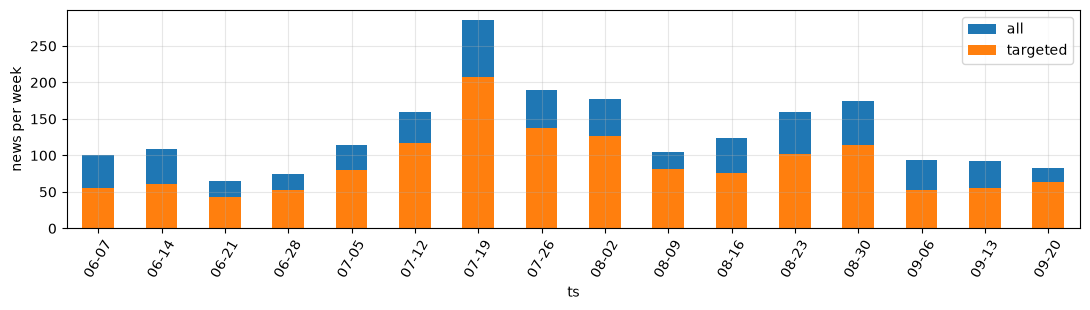


=== MA-V: latest targeted news ===
  2026-09-10 15:07 [V] Pete Wexler, At Stablecon, On Chain Credit, Says There Is An Opportunity To Tap Into This Structure To Ge
  2026-09-14 10:45 [V] $1000 Invested In Visa 15 Years Ago Would Be Worth This Much Today
  2026-09-14 15:03 [MA,V] 'UK banks kick off fundraising in bid to create new payments giant' - Sky News
  2026-09-15 11:59 [CHYM,DAVE,V] Dave Outperforms Visa And Chime, Analyst Says

=== CSX-UNP: latest targeted news ===
  2026-09-04 17:45 [UNP] $1000 Invested In Union Pacific 20 Years Ago Would Be Worth This Much Today
  2026-09-15 10:00 [CSX] Here's How Much $1000 Invested In CSX 10 Years Ago Would Be Worth Today
  2026-09-16 08:28 [UNP] UBS Upgrades Union Pacific to Buy, Raises Price Target to $339
  2026-09-16 12:27 [UNP] Union Pacific CFO Says At Morgan Stanley Conference That Diesel Costs Have Risen To About $5.25-$5.30 A G

=== PYPL-XYZ: latest targeted news ===
  2026-09-08 16:29 [XYZ] Block Submits Application To Office Of C

In [5]:
wk = news.set_index("ts").resample("W")["id"].count()
wk_f = news[news.focused].set_index("ts").resample("W")["id"].count()
ax = wk.plot(kind="bar", figsize=(11, 3.2), color="C0", label="all")
wk_f.plot(kind="bar", ax=ax, color="C1", label="targeted")
ax.set_xticklabels([d.strftime("%m-%d") for d in wk.index], rotation=60); ax.set_ylabel("news per week"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
for p in pairs.pair.head(3):
    r = pairs[pairs.pair == p].iloc[0]
    m = (news[tick_cols[r.sym_A]] | news[tick_cols[r.sym_B]]) & news.focused
    print(f"\n=== {p}: latest targeted news ===")
    for _, n in news[m].tail(4).iterrows():
        print(f"  {n.ts:%Y-%m-%d %H:%M} [{n.symbols}] {n.headline[:105]}")

## 6. Results (text for the report)

The next cell generates the text from the results of the notebook: if the news are downloaded again, the numbers update by themselves.

In [6]:
from IPython.display import Markdown, display

tick_sorted = per_ticker.sort_values(ascending=False)
bp = by_pair.sort_values("per_day")
low = bp.head(4); high = bp.tail(3).iloc[::-1]
n_low = int((by_pair.per_day < 0.3).sum())
lines = [
    "### What we did",
    f"We downloaded from the Alpaca API (Benzinga source) the news of the {len(tick_cols)} stocks of the {len(pairs)} version 2 pairs, from {news.ts.min():%d/%m/%Y} to {TRAIN_END[8:]}/{TRAIN_END[5:7]}/{TRAIN_END[:4]}, and saved them in a table with the publication time in New York time (`data/processed/news_ALL15_V2_train.parquet`, raw answers in `data/raw/news/alpaca/`). The test period was not downloaded.",
    "",
    "### Why",
    "The agent of Step 5 must read only the news published before each signal: it needs the exact publication time and a fixed local archive, so the result is reproducible and there is no lookahead bias. The publication time is used, not the last-update time.",
    "",
    "### Results",
    f"- **Unique news**: {len(news)}, all from {', '.join(news.source.unique())}; {news.focused.mean():.0%} targeted (at most {MAX_SYMBOLS_FOCUSED} tickers); {in_session.mean():.0%} with the market open, {weekend.mean():.1%} at the weekend; {int(news.headline.duplicated().sum())} duplicated headlines.",
    f"- **Coverage per stock**: from {tick_sorted.iloc[-1]} news ({tick_sorted.index[-1]}) to {tick_sorted.iloc[0]} ({tick_sorted.index[0]}); the most covered: " + ", ".join(f"{k} {v}" for k, v in tick_sorted.head(5).items()) + "; the least covered: " + ", ".join(f"{k} {v}" for k, v in tick_sorted.tail(5).items()) + ".",
    f"- **Coverage per pair** (news per calendar day): from {bp.per_day.iloc[0]:.2f} ({bp.index[0]}) to {bp.per_day.iloc[-1]:.2f} ({bp.index[-1]}). Least covered: " + ", ".join(f"{p} {r.per_day:.2f}" for p, r in low.iterrows()) + ". Most covered: " + ", ".join(f"{p} {r.per_day:.2f}" for p, r in high.iterrows()) + f". Pairs below 0.3 news per day: {n_low} of {len(pairs)}.",
    f"- **Times**: only {(lag > 1).mean():.0%} of the news is updated more than one hour after publication; `created_at` is kept.",
]
if consistency:
    lines.append(f"- **Consistency with version 1**: for the {consistency['n_common']} stocks in common the news are " + ("the same" if consistency["equal"] else f"different ({consistency['n_v2']} here against {consistency['n_v1']} in version 1): to be checked") + ".")
lines += [
    "",
    "### What it means",
    "- A single source, very uneven coverage: for the pairs with few news the agent will almost always have «no news found», which does not mean that nothing happened.",
    "- The number of signals with at least one news item in the last hours is in part 7.",
    "- The check by hand of the publication time on 10 news items (part 4) is still to be done.",
]
display(Markdown("\n".join(lines)))

### What we did
We downloaded from the Alpaca API (Benzinga source) the news of the 30 stocks of the 15 version 2 pairs, from 01/06/2026 to 16/09/2026, and saved them in a table with the publication time in New York time (`data/processed/news_ALL15_V2_train.parquet`, raw answers in `data/raw/news/alpaca/`). The test period was not downloaded.

### Why
The agent of Step 5 must read only the news published before each signal: it needs the exact publication time and a fixed local archive, so the result is reproducible and there is no lookahead bias. The publication time is used, not the last-update time.

### Results
- **Unique news**: 2106, all from benzinga; 68% targeted (at most 3 tickers); 49% with the market open, 4.4% at the weekend; 66 duplicated headlines.
- **Coverage per stock**: from 20 news (CL) to 268 (JPM); the most covered: JPM 268, GS 222, CRM 205, MS 148, UNH 128; the least covered: DHR 33, PG 32, EOG 26, SYK 26, CL 20.
- **Coverage per pair** (news per calendar day): from 0.48 (CL-PG) to 3.06 (GS-MS). Least covered: CL-PG 0.48, DHR-TMO 0.63, COP-EOG 0.75, CSX-UNP 0.80. Most covered: GS-MS 3.06, JPM-WFC 2.86, CRM-WDAY 2.51. Pairs below 0.3 news per day: 0 of 15.
- **Times**: only 1% of the news is updated more than one hour after publication; `created_at` is kept.
- **Consistency with version 1**: for the 12 stocks in common the news are the same.

### What it means
- A single source, very uneven coverage: for the pairs with few news the agent will almost always have «no news found», which does not mean that nothing happened.
- The number of signals with at least one news item in the last hours is in part 7.
- The check by hand of the publication time on 10 news items (part 4) is still to be done.

## 7. News-signals table

For each train signal ([03_signals.ipynb](03_signals.ipynb)) the news published in the 24 hours before that tag one of the two stocks of the pair are saved, with how many minutes before they were published and whether they are targeted. The window is 24 hours because almost half of the signals arise right after the open, on the overnight move: the news that explain it are often published after the close of the day before, and a shorter window would not see them. The `ts <= t_signal` filter is in `news_before_signals` ([news.py](news.py)): a news item published after the signal does not enter the table.

In [7]:
signals = pd.read_csv(SIGNALS, parse_dates=["t_signal", "t_entry", "t_exit"])
assert signals.t_exit.max() < train_end, "there are signals after the end of the train: the test is not used"
link = news_before_signals(signals, news, hours=WINDOW_H)
link.to_csv(NEWS_FOR_SIGNALS, index=False)
n_with = link.signal_id.nunique()
print(f"{len(link)} (signal, news) pairs for {n_with} signals of {len(signals)} ({n_with / len(signals):.0%}); the others have no news in the last {WINDOW_H} hours")
print(f"signals with at least one targeted news item: {link[link.focused].signal_id.nunique()}; news per signal: median {link.groupby('signal_id').size().median():.0f}, maximum {link.groupby('signal_id').size().max()}")
print(f"saved in data/processed/{NEWS_FOR_SIGNALS.name}")
link.head()

1755 (signal, news) pairs for 586 signals of 973 (60%); the others have no news in the last 24 hours
signals with at least one targeted news item: 450; news per signal: median 2, maximum 31
saved in data/processed/news_for_signals_15pairs_v2_train.csv


,signal_id,pair,t_signal,direction,most_moved_leg,news_id,news_ts,minutes_before,headline,summary,source,symbols,n_symbols,focused,mentions_A,mentions_B,url
0,0,COP-EOG,2026-06-16 10:31:00,long COP / short EOG,EOG,53212700,2026-06-15 17:12:38,1038.366667,'ConocoPhillips set to sign deal with Syria to...,,benzinga,COP,1,True,True,False,https://www.benzinga.com/news/26/06/53212700/c...
1,1,KO-PEP,2026-06-16 11:04:00,short KO / long PEP,PEP,53200728,2026-06-15 11:29:34,1414.433333,The Hormuz Reopening Trade: These 20 Large-Cap...,Wall Street marched near records as the Strait...,benzinga,"ABT,ACN,BABA,CRM,GLD,MCD,NEM,PDD,PEP,SAP,UL",11,False,False,True,https://www.benzinga.com/markets/equities/26/0...
2,1,KO-PEP,2026-06-16 11:04:00,short KO / long PEP,PEP,53221686,2026-06-16 09:09:35,114.416667,Yum! Brands Is Selling One Of America's Most I...,Yum Brands sells Pizza Hut to LongRange Capita...,benzinga,"DASH,DPZ,PEP,YUM,YUMC",5,False,False,True,https://www.benzinga.com/m-a/26/06/53221686/yu...
3,2,MA-V,2026-06-16 11:04:00,short MA / long V,MA,53213905,2026-06-15 19:49:51,914.150000,Travala Wants To Be The Travel Infrastructure ...,It was probably only a matter of time before c...,benzinga,"AVA,AVAUSD,BKNG,BNBTUSD,BTC,BTCUSD,CRCL,CROUSD...",11,False,False,True,https://www.benzinga.com/Opinion/26/06/5321390...
4,3,COP-EOG,2026-06-16 11:31:00,long COP / short EOG,EOG,53212700,2026-06-15 17:12:38,1098.366667,'ConocoPhillips set to sign deal with Syria to...,,benzinga,COP,1,True,True,False,https://www.benzinga.com/news/26/06/53212700/c...
